# Deterministic neural tree

This notebook trains an ordinary neural network with a tree of fixed topology. Choose one training type with `TRAINING_METHOD`: `joint_nll` updates m and rho simultaneously by NLL; `joint_brier` updates both by expected integrated Brier score; `alternating` updates m by NLL first and rho by Brier second while fixing the other branch. Only the chosen type is fitted, with the fitted `model` and `history` available for inspection. The results report test NLL, test Brier, average grid SSE against conditional truth, runtime, and the restored epoch. Survival and multimodal PDF plots compare the chosen model with conditional truth. Set `shared_layers` in `ModelConfig` to choose the number of shared hidden layers before the private encoders (one by default here). With shared layers, both alternating steps update the trunk, so the opposite head's predictions may change; use zero for strictly separate branches. Censored Brier targets use detached conditional expectations. Evaluation reports both the censoring-aware test NLL and test Brier score. The generator is `testdata2.py`: all six covariates are independent Uniform(-1, 1). Set `SCENARIO` to `ph`, `lognormal`, `po`, or `multimodal`, and `CENSOR_Q` to `0.2` or `0.5`. The multimodal distribution has two equal-weight Weibull components with shapes `(5, 8)` and baseline scales `(0.5, 3)` for `MULTIMODAL_CASE="separate"` or `(0.5, 1.8)` for `MULTIMODAL_CASE="closer"`. See `testdata2.md` for the formulas and censoring process.

In [ ]:
from pathlib import Path
import time
import sys
import matplotlib.pyplot as plt
import pandas as pd
import torch

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "tuning" / "testdata2.py").is_file() and (path / "testing").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Could not locate the NRT project root")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from testing import ModelConfig, TrainingConfig, evaluate_brier, evaluate_nll, fit
import importlib
import testing.testdata2 as simulation_data
importlib.reload(simulation_data)  # pick up generator changes on rerun
from testing.testdata2 import (
    MULTIMODAL_SCALE_MULTIPLIER_CASES,
    MULTIMODAL_SHAPES,
    survival_curves,
    multimodal_survival,
    data_reg,
    data_reg_multimodal,
)

SEED = 123
N_SAMPLES = 5000
X_DIM = 6
CENSOR_Q = 0.2  # 0.2: moderate; 0.5: high right censoring
GRID_SIZE = 256
TRAINING_METHOD = "alternating"  # joint_nll, joint_brier, or alternating
SCENARIO = "po"  # ph, lognormal, po, or multimodal
CENSOR_TYPE = "right"  # exact, right, interval, or current
MULTIMODAL_CASE = "separate"  # separate or closer peaks
SCALE_MULTIPLIERS = MULTIMODAL_SCALE_MULTIPLIER_CASES[MULTIMODAL_CASE]
DATA_DEVICE = torch.device("cpu")  # shared deterministic data generation
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
print(
    f"Device: {DEVICE}; scenario: {SCENARIO}; censoring: {CENSOR_TYPE}; "
    f"training: {TRAINING_METHOD}; "
    f"multimodal case: {MULTIMODAL_CASE if SCENARIO == 'multimodal' else 'n/a'}; scale multipliers: {SCALE_MULTIPLIERS if SCENARIO == 'multimodal' else 'n/a'}; "
    f"component shapes: {MULTIMODAL_SHAPES if SCENARIO == 'multimodal' else 'n/a'}"
)

## Generate the shared example data

This cell resets the seed immediately before using the CPU generator. Its configuration matches `benchmark_methods.ipynb`.

12.423435306549074


{'whiskers': [<matplotlib.lines.Line2D at 0x2798e2abcd0>,
 'caps': [<matplotlib.lines.Line2D at 0x2798e2b0150>,
 'boxes': [<matplotlib.lines.Line2D at 0x2798e2ab690>],
 'medians': [<matplotlib.lines.Line2D at 0x2798e2b1550>],
 'fliers': [<matplotlib.lines.Line2D at 0x2798e2b3a10>],
 'means': []}

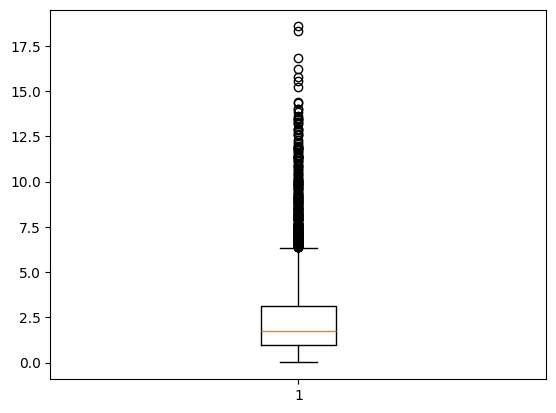

In [170]:
torch.manual_seed(SEED)
data_kwargs = dict(
    n=N_SAMPLES, x_dim=X_DIM, q=CENSOR_Q,
    censor_type=CENSOR_TYPE, device=DATA_DEVICE,
)
if SCENARIO == "multimodal":
    x, L, R, event_time, mixture_weights, component_scales, component = (
        data_reg_multimodal(**data_kwargs, multimodal_case=MULTIMODAL_CASE)
    )
else:
    x, L, R, event_time, shape, scale = data_reg(**data_kwargs, scenario=SCENARIO)
n_train = int(0.8 * len(x))
x_train, x_test = x[:n_train], x[n_train:]
L_train, L_test = L[:n_train], L[n_train:]
R_train, R_test = R[:n_train], R[n_train:]
if SCENARIO == "multimodal":
    weights_test, scales_test = mixture_weights[n_train:], component_scales[n_train:]
else:
    shape_test, scale_test = shape[n_train:], scale[n_train:]
finite_bounds = torch.cat((L_train[torch.isfinite(L_train)], R_train[torch.isfinite(R_train)]))
max_obs = finite_bounds.max().item()
max_bound = 1.1 * max_obs
print(max_bound)
plt.boxplot(event_time.cpu())

In [171]:
sum(torch.isfinite(R))

tensor(4023)

In [172]:
# Fit only the chosen training type.
model_config = ModelConfig(
    depth=7, x_dim=X_DIM, h_dim=16,
    mlp_hidden=8, mlp_layers =2, shared_layers=3, dropout=0.00,
    split_min=0.1,
)
training_config = TrainingConfig(
    epochs=200, training_batch_size=128, patience=20,
    brier_grid_size=GRID_SIZE, lr=1e-3,
    training_method=TRAINING_METHOD,
    cuda_graphs=True,  # reduce CUDA launch overhead; ignored on CPU
    max_grad_norm=1.0,  # maximum gradient L2 norm; 0 disables clipping
)
torch.manual_seed(SEED)
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)
    torch.cuda.synchronize(DEVICE)
print(f"Training {TRAINING_METHOD}; checkpoint metric: {training_config.monitor}")
started = time.perf_counter()
model, history = fit(
    x_train, L_train, R_train, max_bound,
    model_config, training_config, DEVICE,
)
if DEVICE.type == "cuda":
    torch.cuda.synchronize(DEVICE)
fit_seconds = time.perf_counter() - started


Training alternating; checkpoint metric: rho_brier
Epoch 001 | m_nll: 3.8107 | rho_brier: 1.7679
Epoch 010 | m_nll: 3.6864 | rho_brier: 1.0158
Epoch 020 | m_nll: 3.6978 | rho_brier: 0.9854
Epoch 030 | m_nll: 3.6621 | rho_brier: 0.9355
Epoch 040 | m_nll: 3.6831 | rho_brier: 0.9266
Epoch 050 | m_nll: 3.7058 | rho_brier: 0.9240
Epoch 060 | m_nll: 3.7163 | rho_brier: 0.9197
Epoch 070 | m_nll: 3.7235 | rho_brier: 0.9210
Epoch 080 | m_nll: 3.7345 | rho_brier: 0.9169
Epoch 090 | m_nll: 3.7406 | rho_brier: 0.9187
Epoch 100 | m_nll: 3.7386 | rho_brier: 0.9162
Epoch 110 | m_nll: 3.7405 | rho_brier: 0.9172
Epoch 120 | m_nll: 3.7511 | rho_brier: 0.9153
Epoch 130 | m_nll: 3.7411 | rho_brier: 0.9138
Epoch 140 | m_nll: 3.7426 | rho_brier: 0.9142
Epoch 150 | m_nll: 3.7406 | rho_brier: 0.9156
Early stopping at epoch 151: rho_brier did not improve for 20 epochs


In [173]:
# Evaluate the chosen model against observations and conditional truth.
grid = torch.linspace(0.0, max_obs, GRID_SIZE, device=DEVICE)
if SCENARIO == "multimodal":
    true_survival = multimodal_survival(weights_test, scales_test, grid).to(DEVICE)
else:
    true_survival = survival_curves(
        shape_test, scale_test, grid, scenario=SCENARIO,
    ).to(DEVICE)

test_brier = evaluate_brier(
    model, x_test, L_test, R_test,
    grid_size=GRID_SIZE, device=DEVICE,
)
test_nll = evaluate_nll(model, x_test, L_test, R_test, device=DEVICE)
estimated = model.predict_survival(x_test.to(DEVICE), grid, prediction_batch_size=256)
grid_sse = (estimated - true_survival).square().sum(dim=1)
monitor = training_config.monitor
best_epoch = min(history, key=lambda row: row[monitor])
results_df = pd.DataFrame([{
    "method": TRAINING_METHOD,
    "test_nll": test_nll,
    "test_brier": test_brier,
    "average_grid_sse": grid_sse.mean().item(),
    "training_epochs": len(history),
    "restored_epoch": int(best_epoch["epoch"]),
    "checkpoint_metric": monitor,
    "fit_seconds": fit_seconds,
}]).set_index("method")
results_df


,test_nll,test_brier,average_grid_sse,training_epochs,restored_epoch,checkpoint_metric,fit_seconds
method,,,,,,,
alternating,1.417834,0.93231,0.213003,151,131,rho_brier,6.530444


alternating: individual 321 grid SSE = 0.704692


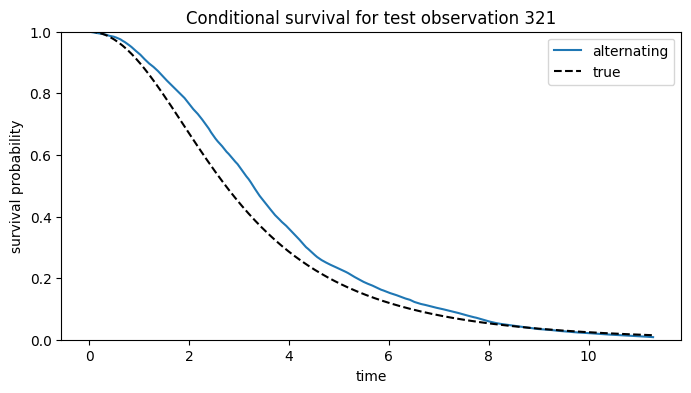

In [174]:
# Compare the chosen model with conditional truth for one test observation.
index = 321
if not 0 <= index < len(x_test):
    raise ValueError("index must refer to a test observation")
plt.figure(figsize=(8, 4))
plt.plot(grid.cpu(), estimated[index].cpu(), label=TRAINING_METHOD)
print(f"{TRAINING_METHOD}: individual {index} grid SSE = {grid_sse[index].item():.6f}")
plt.plot(grid.cpu(), true_survival[index].cpu(), "k--", label="true")
plt.xlabel("time")
plt.ylabel("survival probability")
plt.title(f"Conditional survival for test observation {index}")
plt.ylim(0.0, 1.0)
plt.legend()
plt.show()


In [175]:
# Compare the chosen model with the true multimodal PDF.
if SCENARIO == "multimodal":
    pdf_grid = torch.linspace(0.0, max_bound, 1024, device=DEVICE)
    scales = scales_test[index].to(DEVICE)
    weights = weights_test[index].to(DEVICE)
    shapes = scales.new_tensor(MULTIMODAL_SHAPES)
    scaled_time = pdf_grid[:, None] / scales[None, :]
    component_pdf = (
        (shapes[None, :] / scales[None, :])
        * scaled_time.pow(shapes[None, :] - 1)
        * torch.exp(-scaled_time.pow(shapes[None, :] ))
    )
    true_pdf = (component_pdf * weights[None, :]).sum(dim=1)

    plt.figure(figsize=(8, 4))
    with torch.no_grad():
        params = model(x_test[index:index + 1].to(DEVICE))
        leaf_lower, leaf_upper = model.tree.leaf_intervals(params.split_props)
        leaf_masses = model.tree.leaf_masses(params.left_probs)
        estimated_pdf = leaf_masses[0] / (leaf_upper[0] - leaf_lower[0])
        leaf_edges = torch.cat((leaf_lower[0, :1], leaf_upper[0]))
    plt.stairs(estimated_pdf.cpu().numpy(), leaf_edges.cpu().numpy(), label=TRAINING_METHOD)
    plt.plot(pdf_grid.cpu(), true_pdf.cpu(), "k--", label="true PDF")
    plt.xlabel("time")
    plt.ylabel("probability density")
    plt.title(f"Conditional PDF for test observation {index}")
    plt.xlim(0.0, max_bound)
    plt.legend()
    plt.show()


In [176]:
# Summarize per-observation errors for the chosen model.
grid_sse_df = pd.DataFrame({TRAINING_METHOD: grid_sse.cpu().numpy()})
grid_sse_df.index.name = "test_observation"
grid_sse_df.describe()


,alternating
count,1000.000000
mean,0.213003
std,0.329720
min,0.002705
25%,0.038876
50%,0.103545
75%,0.225279
max,2.789724
